In [5]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import cv2
import joblib

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix


In [6]:
csv_file = Path('labels.csv')
df = pd.read_csv(csv_file, names=['file_path', 'label'])
df.head()

,file_path,label
0,other_other.u05.0108.png,other
1,other_other.if8.0180.png,other
2,ellipse_ellipse.if5.0296.png,ellipse
3,other_other.if2.0020.png,other
4,ellipse_ellipse.if8.1501.png,ellipse


/var/folders/z9/c66hmjx12w3g41xmv5xvlyqw0000gn/T/ipykernel_10951/1837888042.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df, x='label', hue_order='label', palette='pastel')


<Axes: xlabel='label', ylabel='count'>

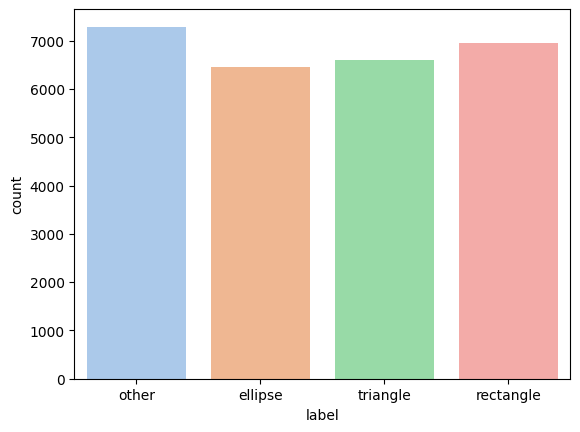

In [7]:
sns.countplot(df, x='label', hue_order='label', palette='pastel')

In [8]:
def preprocess_image(img_path):
    source_folder = Path('sorted_data')
    img_path = source_folder / img_path
    img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        img = cv2.resize(img, (64, 64))
        img = img.flatten()
        img = img / 255.0
    return img

In [9]:
label_coding = {'other': 0, 'ellipse': 1, 'triangle': 2, 'rectangle': 3}

df['processed_image'] = df['file_path'].apply(preprocess_image)
df['label'] = df['label'].map(label_coding)
df

,file_path,label,processed_image
0,other_other.u05.0108.png,0,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
1,other_other.if8.0180.png,0,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
2,ellipse_ellipse.if5.0296.png,1,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
3,other_other.if2.0020.png,0,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
4,ellipse_ellipse.if8.1501.png,1,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
...,...,...,...
27287,other_other.u05.0111.png,0,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
27288,other_other.il1.0964.png,0,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
27289,other_other.if8.0199.png,0,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."
27290,ellipse_ellipse.u10.0022.png,1,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ..."


In [10]:
X = np.array(df['processed_image'].to_list())
y = np.array(df['label'].to_list())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
clf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, verbose=True)
clf.fit(X_train_scaled, y_train)

[LibSVM]......*..*
optimization finished, #iter = 8696
obj = -1957.409278, rho = -0.928787
nSV = 4936, nBSV = 1906
......*..*
optimization finished, #iter = 8622
obj = -2249.654550, rho = -0.522031
nSV = 5252, nBSV = 2145
.......*..*
optimization finished, #iter = 9735
obj = -2307.706491, rho = -0.496371
nSV = 5762, nBSV = 2081
....*..*
optimization finished, #iter = 6563
obj = -1669.037000, rho = 0.405148
nSV = 3869, nBSV = 1683
.....*...*
optimization finished, #iter = 8004
obj = -2574.089433, rho = 0.541551
nSV = 5183, nBSV = 2752
.....*..*
optimization finished, #iter = 7351
obj = -2052.877881, rho = 0.137832
nSV = 4528, nBSV = 2022
Total nSV = 13783


SVC(random_state=42, verbose=True)

In [ ]:
# Make predictions
y_pred = clf.predict(X_test_scaled)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

In [11]:
param_grid = {
    'gamma': ['scale'],
    'kernel': ['poly'],
    'C': [50, 100, 150],
    'degree': [3],
    'coef0': [0.0, 0.5],
}

In [12]:
svm = SVC()
grid_search = GridSearchCV(estimator=svm, param_grid=param_grid, cv=5, scoring='accuracy', verbose=3, n_jobs=-1, return_train_score=True)
grid_search.fit(X_train_scaled, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV 1/5] END C=50, coef0=0.5, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.881) total time= 9.5min
[CV 3/5] END C=50, coef0=0.5, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.878) total time= 9.5min
[CV 2/5] END C=50, coef0=0.5, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.887) total time= 9.7min
[CV 1/5] END C=50, coef0=0.0, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.898) total time=17.8min
[CV 4/5] END C=50, coef0=0.0, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.907) total time=18.0min
[CV 2/5] END C=50, coef0=0.0, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.900) total time=18.6min
[CV 5/5] END C=50, coef0=0.0, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.900) total time=18.6min
[CV 3/5] END C=50, coef0=0.0, degree=3, gamma=scale, kernel=poly;, score=(train=1.000, test=0.897) total time=18.8

GridSearchCV(cv=5, estimator=SVC(), n_jobs=-1,
             param_grid={'C': [50, 100, 150], 'coef0': [0.0, 0.5],
                         'degree': [3], 'gamma': ['scale'],
                         'kernel': ['poly']},
             return_train_score=True, scoring='accuracy', verbose=3)

In [13]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_scaled)


print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[1627   48   79   55]
 [  60 1519   31   40]
 [  47   25 1527   26]
 [  94   70   49 1526]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89      1809
           1       0.91      0.92      0.92      1650
           2       0.91      0.94      0.92      1625
           3       0.93      0.88      0.90      1739

    accuracy                           0.91      6823
   macro avg       0.91      0.91      0.91      6823
weighted avg       0.91      0.91      0.91      6823



In [14]:
grid_search.best_params_

{'C': 50, 'coef0': 0.0, 'degree': 3, 'gamma': 'scale', 'kernel': 'poly'}

In [16]:
joblib.dump(best_model, 'svm_model.joblib')  
joblib.dump(scaler, 'scaled.joblib')

['scaled.joblib']